# Initial Research — Exploração do formato do dataset BETA

Objetivo: entender a estrutura dos dados (arquivos `S1.mat`–`S70.mat`, dataset BETA de SSVEP) antes de qualquer modelagem.

Documentação oficial: `dataset/Description.pdf`. Notas prévias:
- `dataset/note.txt`: dados já passaram por filtro passa-banda de 3–100 Hz e foram reamostrados para 250 Hz — ou seja, nenhum pré-processamento adicional é necessário nesta etapa.
- O PDF descreve o EEG como um tensor 4D `canal × tempo × bloco × condição`, com 0,5 s antes do início do estímulo; sujeitos S1–S15 têm janela de 2 s (ensaio de 3 s) e S16–S70 têm janela de 3 s (ensaio de 4 s).

Nada aqui altera os dados — apenas carregamento, inspeção e visualização.

In [ ]:
import glob
import re
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt

DATA_DIR = 'dataset'
FS = 250  # Hz
N_BLOCKS = 4
N_CONDITIONS = 40
PRE_ONSET_S = 0.5  # cada ensaio inclui 0,5 s antes do onset do estímulo

## 1. Utilitário de carregamento

Cada `.mat` contém uma única variável `data` (struct MATLAB) com dois campos:
- `EEG`: tensor `float64` de dimensões `(canais, tempo, blocos, condições)`;
- `suppl_info`: informações suplementares (idade, gênero, canais, frequências, fases, SNR, taxa de amostragem).

In [ ]:
def unwrap(v):
    # Converte arrays MATLAB aninhados/objeto em array numpy simples
    a = np.asarray(v)
    if a.dtype == object:
        a = np.array([
            x.item() if isinstance(x, np.ndarray) and x.size == 1 else x
            for x in a.ravel()
        ])
    return a.ravel()


def load_subject(path):
    # Carrega um arquivo S<N>.mat e devolve (EEG, suppl_info como dict).
    m = sio.loadmat(path)['data'][0, 0]
    eeg = m['EEG']
    suppl = {k: unwrap(m['suppl_info'][0, 0][k]) for k in m['suppl_info'].dtype.names}
    return eeg, suppl

## 2. Inspeção de um sujeito (S1)

In [4]:
eeg, info = load_subject(f'{DATA_DIR}/S1.mat')

print(f"EEG: shape={eeg.shape}, dtype={eeg.dtype}, "
      f"{eeg.nbytes / 1e6:.1f} MB em memória")
print(f"campos de suppl_info: {list(info.keys())}")
print(f"srate      = {info['srate']} Hz")
print(f"idade      = {info['age'][0]}")
print(f"gênero     = {info['gender'][0]}")
print(f"bci_quot.  = {info['bci_quotient'][0]:.2f}")
print(f"narrow_snr = {info['narrow_snr'][0]:.2f} dB, wide_snr = {info['wide_snr'][0]:.2f} dB")
fset = np.sort(info['freqs'])
print(f"freqs: {len(info['freqs'])} alvos, conjunto = {fset[0]:.1f}–{fset[-1]:.1f} Hz, passo {np.unique(np.round(np.diff(fset), 3))[0]} Hz")
print(f"ordem das condições no arquivo (rotacionada, não ordenada): {info['freqs'][:5]} ... {info['freqs'][-3:]}")
print(f"phases ({len(info['phases'])}): únicos = {np.unique(info['phases']) / np.pi} * pi")

EEG: shape=(64, 750, 4, 40), dtype=float64, 61.4 MB em memória
campos de suppl_info: ['sub', 'age', 'gender', 'chan', 'freqs', 'phases', 'bci_quotient', 'wide_snr', 'narrow_snr', 'srate']
srate      = [250] Hz
idade      = 26.5
gênero     = female
bci_quot.  = 108.44
narrow_snr = 4.67 dB, wide_snr = -12.48 dB
freqs: 40 alvos, conjunto = 8.0–15.8 Hz, passo 0.2 Hz
ordem das condições no arquivo (rotacionada, não ordenada): [8.6 8.8 9.  9.2 9.4] ... [8.  8.2 8.4]
phases (40): únicos = [0.  0.5 1.  1.5] * pi


## 3. Informação de canais

A matriz `chan` é 64×4: índice, grau, raio (coordenadas polares) e nome do canal.

In [5]:
chan = info['chan'].astype(str).reshape(64, 4)
print(f"chan: {chan.shape} -> colunas: [índice, grau, raio, nome]")

names = chan[:, 3]
print("\nTodos os canais:")
print(', '.join(names))

occip = [n for n in names if n.startswith(('O', 'PO'))]
print(f"\nCanais occipitais/parietais ({len(occip)}) — região típica do SSVEP:")
print(', '.join(occip))

chan: (64, 4) -> colunas: [índice, grau, raio, nome]

Todos os canais:
FP1, FPZ, FP2, AF3, AF4, F7, F5, F3, F1, FZ, F2, F4, F6, F8, FT7, FC5, FC3, FC1, FCZ, FC2, FC4, FC6, FT8, T7, C5, C3, C1, CZ, C2, C4, C6, T8, M1, TP7, CP5, CP3, CP1, CPZ, CP2, CP4, CP6, TP8, M2, P7, P5, P3, P1, PZ, P2, P4, P6, P8, PO7, PO5, PO3, POZ, PO4, PO6, PO8, CB1, O1, OZ, O2, CB2

Canais occipitais/parietais (10) — região típica do SSVEP:
PO7, PO5, PO3, POZ, PO4, PO6, PO8, O1, OZ, O2


## 4. Validação da consistência em todos os 70 sujeitos

Varredura de integridade: todos os arquivos carregam? Formatos batem com a documentação (S1–S15 → 750 pontos; S16–S70 → 1000 pontos)? Frequências/fases/srate são idênticos entre sujeitos?

In [6]:
paths = sorted(glob.glob(f'{DATA_DIR}/S*.mat'),
               key=lambda p: int(re.search(r'S(\d+)\.mat', p).group(1)))
print(f"{len(paths)} arquivos de sujeito encontrados")

ref_freqs, ref_phases, ref_srate = info['freqs'], info['phases'], int(info['srate'][0])
records = []
for p in paths:
    eeg, s = load_subject(p)
    sid = int(re.search(r'S(\d+)\.mat', p).group(1))
    assert eeg.shape == (64, 750 if sid <= 15 else 1000, 4, 40), (sid, eeg.shape)
    assert eeg.dtype == np.float64
    assert np.array_equal(s['freqs'], ref_freqs), f"freqs divergem em S{sid}"
    assert np.array_equal(s['phases'], ref_phases), f"phases divergem em S{sid}"
    assert int(s['srate'][0]) == ref_srate == FS
    records.append(dict(sid=sid, t=eeg.shape[1], age=float(s['age'][0]),
                        gender=str(s['gender'][0]), bci=float(s['bci_quotient'][0]),
                        snr=float(s['narrow_snr'][0])))

print("OK — todos os arquivos carregaram e são consistentes.\n")
ages = np.array([r['age'] for r in records])
bcis = np.array([r['bci'] for r in records])
snrs = np.array([r['snr'] for r in records])
genders = [r['gender'] for r in records]
print(f"grupos de tempo: S1–S15 = {records[0]['t']} pts (3 s), S16–S70 = {records[15]['t']} pts (4 s)")
print(f"idade    : min={ages.min():.1f}, max={ages.max():.1f}, média={ages.mean():.1f}")
print(f"gênero   : female={genders.count('female')}, male={genders.count('male')}")
print(f"bci_quot : min={bcis.min():.1f}, max={bcis.max():.1f}, média={bcis.mean():.1f}")
print(f"narrowSNR: min={snrs.min():.2f} dB, max={snrs.max():.2f} dB, média={snrs.mean():.2f} dB")

70 arquivos de sujeito encontrados
OK — todos os arquivos carregaram e são consistentes.

grupos de tempo: S1–S15 = 750 pts (3 s), S16–S70 = 1000 pts (4 s)
idade    : min=10.2, max=64.1, média=25.1
gênero   : female=28, male=42
bci_quot : min=74.7, max=139.2, média=100.0
narrowSNR: min=-0.41 dB, max=10.07 dB, média=4.00 dB


## 5. Visualização — um ensaio no domínio do tempo

Canal Oz do sujeito S1, condição 0 (8,6 Hz), bloco 0. O onset do estímulo ocorre em t = 0,5 s (após a fase de base pré-estímulo).

índice do canal OZ = 61


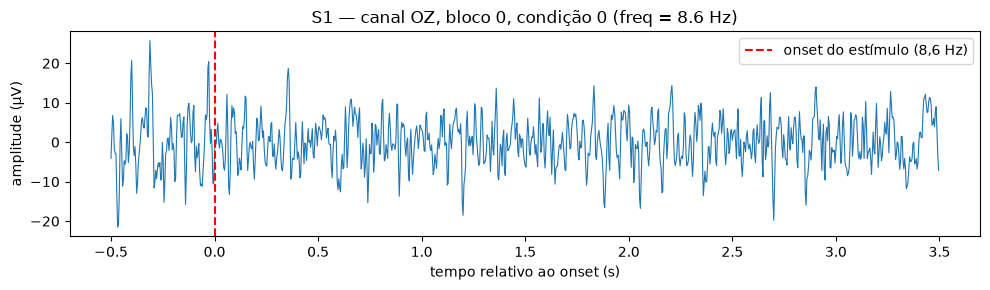

In [7]:
oz = int(np.where(names == 'OZ')[0][0]) if 'OZ' in names else int(np.where(names == 'Oz')[0][0])
print(f"índice do canal OZ = {oz}")

trial = eeg[oz, :, 0, 0]  # (tempo,) do bloco 0, condição 0
t = np.arange(trial.size) / FS - PRE_ONSET_S

plt.figure(figsize=(10, 3))
plt.plot(t, trial, lw=0.8)
plt.axvline(0, color='r', ls='--', label='onset do estímulo (8,6 Hz)')
plt.xlabel('tempo relativo ao onset (s)'); plt.ylabel('amplitude (µV)')
plt.title(f"S1 — canal {names[oz]}, bloco 0, condição 0 (freq = {info['freqs'][0]} Hz)")
plt.legend(); plt.tight_layout(); plt.show()

## 6. Visualização — espectro (FFT) com picos de SSVEP

FFT simples do canal Oz, média sobre os 4 blocos, usando apenas a janela de estímulo (0 a 2 s após o onset, para S1–S15). Os harmônicos da frequência de estímulo (8,6 / 17,2 / 25,8 Hz) devem se destacar — confirmação direta de que o formato está sendo lido corretamente.

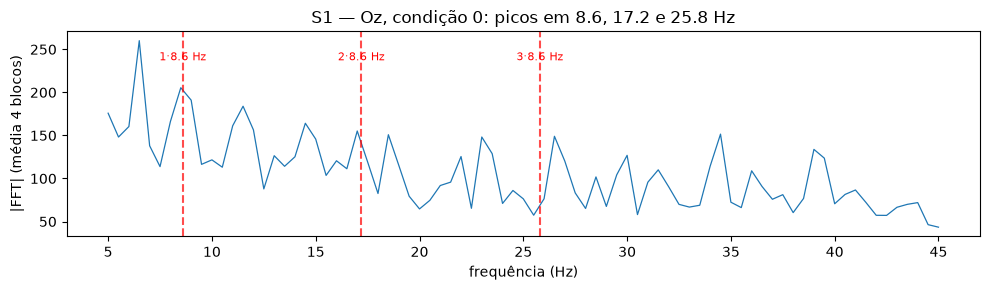

In [8]:
cond = 0
f_stim = info['freqs'][cond]
onset = int(PRE_ONSET_S * FS)
window = eeg[oz, onset:onset + 2 * FS, :, cond]  # (tempo, blocos) — janela de 2 s de estímulo

win = np.hanning(window.shape[0])
spec = np.abs(np.fft.rfft(window * win[:, None], axis=0)).mean(axis=1)
freqs_ax = np.fft.rfftfreq(2 * FS, d=1 / FS)

band = (freqs_ax >= 5) & (freqs_ax <= 45)
plt.figure(figsize=(10, 3))
plt.plot(freqs_ax[band], spec[band], lw=0.9)
for h in (1, 2, 3):
    plt.axvline(h * f_stim, color='r', ls='--', alpha=0.7)
    plt.text(h * f_stim, spec[band].max() * 0.95, f'{h}·{f_stim:.1f} Hz',
             color='r', ha='center', va='top', fontsize=8)
plt.xlabel('frequência (Hz)'); plt.ylabel('|FFT| (média 4 blocos)')
plt.title(f"S1 — Oz, condição {cond}: picos em {f_stim:.1f}, {2*f_stim:.1f} e {3*f_stim:.1f} Hz")
plt.tight_layout(); plt.show()

## Resumo do formato dos dados

- **Arquivos**: `dataset/S1.mat` … `dataset/S70.mat` (70 sujeitos, um `.mat` por sujeito, ~60 MB cada).
- **EEG**: tensor `float64` `(64, T, 4, 40)` — 64 canais × T pontos × 4 blocos × 40 condições.
  - T = 750 (3 s) para S1–S15; T = 1000 (4 s) para S16–S70. Cada ensaio contém 0,5 s de linha de base pré-estímulo + janela de estímulo (2 s ou 3 s) + 0,5 s pós-janela.
- **Já pré-processado** (segundo `note.txt`): passa-banda 3–100 Hz e reamostragem para 250 Hz. Nenhum tratamento extra foi aplicado aqui.
- **Condições**: 40 alvos, conjunto de frequências 8,0–15,8 Hz (passo 0,2 Hz) e fases iniciais em `{0, π/2, π, 3π/2} rad`, idênticas em todos os sujeitos. Atenção: a ordem das condições no arquivo não é ordenada — `freqs` vai de 8,6→15,8 Hz e só depois fecha com 8,0→8,4 Hz. Sempre indexar por `freqs[c]`, nunca assumir ordenação.
- **`suppl_info`**: `sub`, `age`, `gender`, `chan` (64×4: índice, grau, raio, nome), `freqs`, `phases`, `bci_quotient`, `wide_snr`, `narrow_snr`, `srate`.
- **Canais occipitais/parietais** (região ativa de SSVEP): PO7, PO3, POz, PO4, PO8, PO5, PO6, O1, Oz, O2 etc. — serão o recorte natural na fase de extração espectral.
- **Consistência verificada**: 70/70 arquivos carregam; formatos, frequências, fases e taxa de amostragem batem com a documentação BETA.
